# Data Cleansing, Standarisasi & Visualisasi Data Karyawan (Employee Data)

**Deskripsi**
Notebook ini membersihkan (*data cleansing*), menstandarisasi, dan menganalisis dataset karyawan `employee_data.csv` menggunakan **Pandas**, lalu memvisualisasikannya dengan **Matplotlib**, **Seaborn**, dan **Plotly** lengkap dengan interpretasi setiap grafik. Dataset **sebelum** dan **sesudah** cleansing disimpan di Google Drive.

**Gambaran dataset**
- File mentah berisi **3.000 baris × 26 kolom**, tetapi hanya **100 baris** yang berisi data. **2.900 baris sisanya kosong total** dan dibuang pada proses cleansing.
- Kolom mencakup identitas, tanggal masuk/keluar, jabatan, unit bisnis, status, tipe karyawan, terminasi, demografi, dan penilaian kinerja.

| Tahap | Keterangan |
|---|---|
| 1–2 | Mount Google Drive, muat dataset mentah (disalin ke folder `raw`) |
| 3–4 | Konfigurasi dan cleansing dasar (nama kolom, spasi, nilai kosong, baris kosong total) |
| 5 | Standarisasi kolom (tanggal, nama, email, kategori, angka) |
| 6 | Duplikat, nilai kosong, dan enrichment (usia, masa kerja, status keluar) |
| 7–8 | Validasi dan laporan perbandingan sebelum vs sesudah |
| 9 | Simpan dataset bersih ke folder `clean` |
| 10–11 | Visualisasi (11 grafik) beserta interpretasi dan kesimpulan |

**Struktur folder di Drive**
```
MyDrive/Data_Cleansing_Karyawan/
 ├── raw/         → dataset asli (sebelum cleansing)
 ├── clean/       → dataset bersih (sesudah cleansing, CSV & XLSX)
 └── visualisasi/ → gambar grafik (PNG) dan grafik interaktif (HTML)
```

## 1. Mount Google Drive & Pengaturan Folder
Drive dipakai untuk menyimpan dataset **sebelum** (`raw`) dan **sesudah** (`clean`) cleansing, serta gambar hasil visualisasi. Jika notebook dijalankan di luar Colab, folder dibuat di direktori kerja.

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# ====== MOUNT GOOGLE DRIVE (otomatis pakai folder lokal bila bukan di Colab) ======
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/DataVisualization/employee_data'
    DI_COLAB = True
except ImportError:
    BASE_DIR = './Data_Cleansing_Karyawan'
    DI_COLAB = False

RAW_DIR   = f'{BASE_DIR}/raw'          # dataset sebelum cleansing
CLEAN_DIR = f'{BASE_DIR}/clean'        # dataset sesudah cleansing
VIS_DIR   = f'{BASE_DIR}/visualisasi'  # gambar hasil visualisasi

RAW_FILE   = 'employee_data.csv'
CLEAN_FILE = 'employee_data_bersih.csv'

for d in (RAW_DIR, CLEAN_DIR, VIS_DIR):
    os.makedirs(d, exist_ok=True)
print('Folder siap:', BASE_DIR)

Mounted at /content/drive
Folder siap: /content/drive/MyDrive/DataVisualization/employee_data


## 2. Muat Dataset (Sebelum Cleansing)
Jika file belum ada di folder `raw`, kamu akan diminta mengunggah `employee_data.csv` dan file asli otomatis disimpan ke Drive. Semua kolom dibaca sebagai teks (`dtype=str`) agar format asli (terutama tanggal) tidak berubah sebelum dibersihkan.

In [2]:
raw_path = f'{RAW_DIR}/{RAW_FILE}'

if not os.path.exists(raw_path):
    if DI_COLAB:
        from google.colab import files
        print('File belum ada di Drive. Silakan unggah employee_data.csv:')
        uploaded = files.upload()
        for name, content in uploaded.items():
            with open(f'{RAW_DIR}/{name}', 'wb') as f:
                f.write(content)
        RAW_FILE = list(uploaded.keys())[0]
        raw_path = f'{RAW_DIR}/{RAW_FILE}'
    else:
        raise FileNotFoundError(f'Letakkan file di {raw_path}')

def baca_file(path):
    if path.lower().endswith(('.xlsx', '.xls')):
        return pd.read_excel(path, dtype=str)
    # utf-8-sig membuang karakter BOM di awal file; koma dipakai sebagai pemisah
    return pd.read_csv(path, encoding='utf-8-sig', sep=',', dtype=str, keep_default_na=False)

df_raw = baca_file(raw_path)
baris_kosong = int((df_raw.apply(lambda s: s.str.strip()) == '').all(axis=1).sum())

print(f'Dataset dimuat   : {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom')
print(f'Baris kosong total: {baris_kosong} baris ({baris_kosong / len(df_raw):.1%} dari seluruh baris)')
print(f'Baris berisi data : {df_raw.shape[0] - baris_kosong}')
display(df_raw.head(10))

File belum ada di Drive. Silakan unggah employee_data.csv:


Saving employee_data.csv to employee_data.csv
Dataset dimuat   : 3000 baris x 26 kolom
Baris kosong total: 2900 baris (96.7% dari seluruh baris)
Baris berisi data : 100


,EmpID,FirstName,LastName,StartDate,ExitDate,Title,Supervisor,ADEmail,BusinessUnit,EmployeeStatus,...,Division,DOB,State,JobFunctionDescription,GenderCode,LocationCode,RaceDesc,MaritalDesc,Performance Score,Current Employee Rating
0,3427,Uriah,Bridges,20-Sep-19,,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,...,Finance & Accounting,7/10/1969,MA,Accounting,Female,34904,White,Widowed,Fully Meets,4
1,3428,Paula,Small,11-Feb-23,,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,...,Aerial,30-08-1965,MA,Labor,Male,6593,Hispanic,Widowed,Fully Meets,3
2,3429,Edward,Buck,10-Dec-18,,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,...,General - Sga,6/10/1991,MA,Assistant,Male,2330,Hispanic,Widowed,Fully Meets,4
3,3430,Michael,Riordan,21-Jun-21,,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,...,Finance & Accounting,4/4/1998,ND,Clerk,Male,58782,Other,Single,Fully Meets,2
4,3431,Jasmine,Onque,29-Jun-19,,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,...,General - Con,29-08-1969,FL,Laborer,Female,33174,Other,Married,Fully Meets,3
5,3432,Maruk,Fraval,17-Jan-20,,Area Sales Manager,Sheri Campos,maruk.fraval@bilearner.com,BPC,Active,...,Field Operations,3/4/1949,CT,Driver,Male,6050,Black,Married,Fully Meets,3
6,3433,Latia,Costa,6-Apr-22,3-Jul-23,Area Sales Manager,Jacob Braun,latia.costa@bilearner.com,WBL,Active,...,General - Eng,1/7/1942,CA,Technician,Female,90007,Hispanic,Divorced,Exceeds,4
7,3434,Sharlene,Terry,6-Nov-20,29-Jan-23,Area Sales Manager,Tracy Marquez,sharlene.terry@bilearner.com,CCDR,Active,...,Engineers,7/3/1957,OR,Engineer,Female,97756,White,Divorced,Fully Meets,2
8,3435,Jac,McKinzie,18-Aug-18,,Area Sales Manager,Sharon Becker,jac.mckinzie@bilearner.com,NEL,Active,...,Executive,15-05-1974,TX,Executive Assistant,Male,78789,Black,Widowed,Exceeds,3
9,3436,Joseph,Martins,21-Jan-22,29-Jun-23,Area Sales Manager,George Jenkins,joseph.martins@bilearner.com,BPC,Active,...,Engineers,11/11/1949,TX,Engineer,Male,78207,Asian,Widowed,Fully Meets,5


## 3. Konfigurasi

In [3]:
# Nilai yang dianggap kosong
NILAI_KOSONG = ['', '-', '--', 'n/a', 'na', 'null', 'none', 'nan', '?', 'tidak ada', 'kosong']

# Format tanggal yang dikenali (dicoba berurutan). Format bergaris/miring bertipe angka dibaca HARI-BULAN-TAHUN.
FORMAT_TANGGAL = ['%d-%b-%y', '%d-%b-%Y', '%d-%m-%Y', '%d/%m/%Y', '%Y-%m-%d', '%d %B %Y', '%d %b %Y']

HAPUS_DUPLIKAT          = True
ISI_DESKRIPSI_KOSONG    = 'Tidak Ada'        # untuk termination_description yang kosong
ISI_TEKS_KOSONG         = 'Tidak Diketahui'  # kolom teks lain yang kosong
# exit_date SENGAJA dibiarkan kosong: kosong berarti karyawan belum keluar (bukan data hilang).

## 4. Cleansing Dasar
Nama kolom diseragamkan ke `snake_case`, spasi berlebih dirapikan, placeholder kosong diubah menjadi `NaN`, lalu **baris yang kosong total dibuang**.

In [4]:
log = []
df = df_raw.copy()

# 4.1 Nama kolom -> snake_case (EmpID -> emp_id, ADEmail -> ad_email, Performance Score -> performance_score)
def snake(s):
    s = str(s).replace('\ufeff', '').strip()
    s = re.sub(r'(?<=[a-z0-9])(?=[A-Z])', '_', s)
    s = re.sub(r'(?<=[A-Z])(?=[A-Z][a-z])', '_', s)
    s = re.sub(r'[^\w]+', '_', s).strip('_')
    return s.lower()

df.columns = [snake(c) for c in df.columns]
log.append('Nama kolom diseragamkan ke snake_case')

# 4.2 Rapikan spasi (mis. "Production       " -> "Production") & ubah placeholder kosong -> NaN
spasi_diperbaiki = 0
for c in df.columns:
    asli = df[c].astype('string')
    bersih = asli.str.strip().str.replace(r'\s+', ' ', regex=True)
    spasi_diperbaiki += int(((asli != bersih) & asli.notna() & (asli.str.strip() != '')).sum())
    df[c] = bersih.mask(bersih.str.lower().isin(NILAI_KOSONG))
log.append(f'Spasi berlebih dirapikan pada {spasi_diperbaiki} sel & placeholder kosong diubah menjadi NaN')

# 4.3 Hapus baris yang kosong total
n0 = len(df)
df = df.dropna(how='all').reset_index(drop=True)
log.append(f'Baris kosong total dihapus: {n0 - len(df)} (dari {n0} menjadi {len(df)} baris)')

print('\n'.join(f'- {l}' for l in log))
print(f'\nKolom ({df.shape[1]}):', list(df.columns))

- Nama kolom diseragamkan ke snake_case
- Spasi berlebih dirapikan pada 2 sel & placeholder kosong diubah menjadi NaN
- Baris kosong total dihapus: 2900 (dari 3000 menjadi 100 baris)

Kolom (26): ['emp_id', 'first_name', 'last_name', 'start_date', 'exit_date', 'title', 'supervisor', 'ad_email', 'business_unit', 'employee_status', 'employee_type', 'pay_zone', 'employee_classification_type', 'termination_type', 'termination_description', 'department_type', 'division', 'dob', 'state', 'job_function_description', 'gender_code', 'location_code', 'race_desc', 'marital_desc', 'performance_score', 'current_employee_rating']


## 5. Standarisasi Kolom
| Kelompok kolom | Aturan standarisasi |
|---|---|
| `start_date`, `exit_date`, `dob` | Format campuran (`20-Sep-19`, `30-08-1965`, `7/10/1969`) menjadi tipe tanggal, disimpan `YYYY-MM-DD` |
| `first_name`, `last_name`, `supervisor` | Title Case hanya bila seluruhnya huruf besar/kecil (nama seperti `McKinzie` tidak dirusak) |
| `ad_email` | Huruf kecil |
| `business_unit`, `state` | Huruf besar |
| `gender_code`, `race_desc`, `marital_desc`, `performance_score`, `pay_zone` | Title Case |
| `employee_status`, `employee_type`, `employee_classification_type`, `termination_type` | Dipetakan ke nilai baku; `Unk` menjadi `Unknown` |
| `emp_id`, `current_employee_rating` | Bilangan bulat |

**Catatan format tanggal lahir:** tanggal bergaris (`30-08-1965`) jelas berformat HARI-BULAN-TAHUN. Tanggal bergaris miring (`7/10/1969`) seluruhnya memiliki hari dan bulan ≤ 12 sehingga ambigu, dan dibaca **hari/bulan/tahun** agar konsisten dengan format bergaris. Dampaknya pada usia dalam tahun sangat kecil.

In [5]:
# ---------- Fungsi bantu ----------
def smart_title(x):
    """Title Case hanya bila seluruhnya huruf besar atau seluruhnya huruf kecil."""
    if pd.isna(x):
        return x
    s = str(x)
    return s.title() if (s.isupper() or s.islower()) else s

def norm(s):
    return re.sub(r'[^a-z0-9]', '', str(s).lower())

def std_kategori(x, daftar, khusus=None):
    """Petakan variasi penulisan ke nilai baku. Contoh: 'full time' / 'FULL-TIME' -> 'Full-Time'."""
    if pd.isna(x):
        return x
    k = norm(x)
    if khusus and k in khusus:
        return khusus[k]
    for baku in daftar:
        if norm(baku) == k:
            return baku
    return smart_title(x)

def parse_tanggal(x):
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip()
    for f in FORMAT_TANGGAL:
        try:
            return pd.to_datetime(s, format=f)
        except (ValueError, TypeError):
            continue
    return pd.NaT

# ---------- Tanggal ----------
for c in ['start_date', 'exit_date', 'dob']:
    df[c] = pd.to_datetime(df[c].apply(parse_tanggal))

# ---------- Teks ----------
for c in ['first_name', 'last_name', 'supervisor']:
    df[c] = df[c].apply(smart_title)
df['ad_email'] = df['ad_email'].str.lower()
for c in ['business_unit', 'state']:
    df[c] = df[c].str.upper()
for c in ['gender_code', 'race_desc', 'marital_desc', 'performance_score', 'pay_zone']:
    df[c] = df[c].apply(smart_title)

# ---------- Kategori baku ----------
KANON = {
    'employee_status':              ['Active', 'Future Start', 'Terminated', 'Leave of Absence'],
    'employee_type':                ['Full-Time', 'Part-Time', 'Contract', 'Temporary'],
    'employee_classification_type': ['Full-Time', 'Part-Time', 'Temporary', 'Contract'],
    'termination_type':             ['Voluntary', 'Involuntary', 'Resignation', 'Retirement'],
}
KHUSUS = {'termination_type': {'unk': 'Unknown', 'unknown': 'Unknown'}}
for c, daftar in KANON.items():
    df[c] = df[c].apply(lambda v: std_kategori(v, daftar, KHUSUS.get(c)))

# ---------- Angka ----------
for c in ['emp_id', 'current_employee_rating']:
    df[c] = pd.to_numeric(df[c], errors='coerce').astype('Int64')

log.append('Standarisasi tanggal, nama, email, kategori, dan angka selesai')
display(df.head(8))

,emp_id,first_name,last_name,start_date,exit_date,title,supervisor,ad_email,business_unit,employee_status,...,division,dob,state,job_function_description,gender_code,location_code,race_desc,marital_desc,performance_score,current_employee_rating
0,3427,Uriah,Bridges,2019-09-20,NaT,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,...,Finance & Accounting,1969-10-07,MA,Accounting,Female,34904,White,Widowed,Fully Meets,4
1,3428,Paula,Small,2023-02-11,NaT,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,...,Aerial,1965-08-30,MA,Labor,Male,6593,Hispanic,Widowed,Fully Meets,3
2,3429,Edward,Buck,2018-12-10,NaT,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,...,General - Sga,1991-10-06,MA,Assistant,Male,2330,Hispanic,Widowed,Fully Meets,4
3,3430,Michael,Riordan,2021-06-21,NaT,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,...,Finance & Accounting,1998-04-04,ND,Clerk,Male,58782,Other,Single,Fully Meets,2
4,3431,Jasmine,Onque,2019-06-29,NaT,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,...,General - Con,1969-08-29,FL,Laborer,Female,33174,Other,Married,Fully Meets,3
5,3432,Maruk,Fraval,2020-01-17,NaT,Area Sales Manager,Sheri Campos,maruk.fraval@bilearner.com,BPC,Active,...,Field Operations,1949-04-03,CT,Driver,Male,6050,Black,Married,Fully Meets,3
6,3433,Latia,Costa,2022-04-06,2023-07-03,Area Sales Manager,Jacob Braun,latia.costa@bilearner.com,WBL,Active,...,General - Eng,1942-07-01,CA,Technician,Female,90007,Hispanic,Divorced,Exceeds,4
7,3434,Sharlene,Terry,2020-11-06,2023-01-29,Area Sales Manager,Tracy Marquez,sharlene.terry@bilearner.com,CCDR,Active,...,Engineers,1957-03-07,OR,Engineer,Female,97756,White,Divorced,Fully Meets,2


## 6. Duplikat & Nilai Kosong

In [6]:
# 6.1 Duplikat (baris penuh, lalu emp_id yang seharusnya unik)
if HAPUS_DUPLIKAT:
    n0 = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    dup_id = int(df['emp_id'].duplicated().sum())
    if dup_id:
        df = df.drop_duplicates(subset='emp_id', keep='first').reset_index(drop=True)
    log.append(f'Duplikat dihapus: {n0 - len(df)} baris (emp_id kembar: {dup_id})')

# 6.2 Nilai kosong per kolom
kosong = df.isna().sum()
print('Nilai kosong per kolom sebelum penanganan:')
print(kosong[kosong > 0].to_string() or 'Tidak ada')

# termination_description kosong = tidak ada deskripsi terminasi -> "Tidak Ada"
df['termination_description'] = df['termination_description'].fillna(ISI_DESKRIPSI_KOSONG)
# kolom teks lain yang kosong -> "Tidak Diketahui" (kecuali tanggal)
for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].fillna(ISI_TEKS_KOSONG)

sisa = df.isna().sum()
log.append(f'Nilai kosong ditangani; sisa kosong hanya pada exit_date ({int(sisa["exit_date"])} baris = karyawan belum keluar)')
print('\nSisa nilai kosong:', sisa[sisa > 0].to_dict())

Nilai kosong per kolom sebelum penanganan:
exit_date                  50
termination_description    50

Sisa nilai kosong: {'exit_date': 50}


## 6b. Enrichment (Kolom Turunan)
Tanggal acuan adalah tanggal terbaru di dataset, sehingga hasilnya konsisten setiap dijalankan. Masa kerja dihitung dari `start_date` sampai `exit_date`, atau sampai tanggal acuan bila belum keluar.

In [7]:
TANGGAL_ACUAN = max(df['start_date'].max(), df['exit_date'].max())
df['age'] = ((TANGGAL_ACUAN - df['dob']).dt.days / 365.25).round(1)
df['tenure_years'] = ((df['exit_date'].fillna(TANGGAL_ACUAN) - df['start_date']).dt.days / 365.25).round(2)
df['is_terminated'] = df['exit_date'].notna()
df['age_group'] = pd.cut(df['age'], bins=[0, 30, 40, 50, 60, 120], right=False, labels=['<30', '30-39', '40-49', '50-59', '60+']).astype(str)
print('Tanggal acuan:', TANGGAL_ACUAN.date())
display(df[['emp_id', 'dob', 'age', 'age_group', 'start_date', 'exit_date', 'tenure_years', 'is_terminated']].head())

Tanggal acuan: 2023-08-04


,emp_id,dob,age,age_group,start_date,exit_date,tenure_years,is_terminated
0,3427,1969-10-07,53.8,50-59,2019-09-20,NaT,3.87,False
1,3428,1965-08-30,57.9,50-59,2023-02-11,NaT,0.48,False
2,3429,1991-10-06,31.8,30-39,2018-12-10,NaT,4.65,False
3,3430,1998-04-04,25.3,<30,2021-06-21,NaT,2.12,False
4,3431,1969-08-29,53.9,50-59,2019-06-29,NaT,4.10,False


## 7. Validasi Hasil
Validasi hanya **melaporkan** temuan; data tidak diubah otomatis karena perbaikannya membutuhkan konfirmasi pemilik data.

In [8]:
hasil = []
hasil.append(('emp_id duplikat', int(df['emp_id'].duplicated().sum())))
hasil.append(('Tanggal gagal dibaca (start_date / dob)', int(df['start_date'].isna().sum() + df['dob'].isna().sum())))
hasil.append(('exit_date lebih awal dari start_date', int((df['exit_date'] < df['start_date']).sum())))
hasil.append(('Rating di luar 1-5', int((~df['current_employee_rating'].between(1, 5)).sum())))
hasil.append(('Usia < 18 atau > 70 tahun', int(((df['age'] < 18) | (df['age'] > 70)).sum())))
hasil.append(('Format email tidak valid', int((~df['ad_email'].str.match(r'^[\w.\-+]+@[\w\-]+(\.[\w\-]+)+$')).sum())))
hasil.append(('Email tidak sesuai pola nama.belakang', int((df['ad_email'] != (df['first_name'] + '.' + df['last_name']).str.lower().str.replace(' ', '') + '@bilearner.com').sum())))

print('=== VALIDASI STRUKTUR ===')
for nama, n in hasil:
    print(f"{'✅' if n == 0 else '⚠️'} {nama}: {n}")

print('\n=== KONSISTENSI LOGIKA (perlu klarifikasi pemilik data) ===')
aktif_exit  = int(((df['employee_status'] == 'Active') & df['exit_date'].notna()).sum())
future_exit = int(((df['employee_status'] == 'Future Start') & df['exit_date'].notna()).sum())
future_past = int(((df['employee_status'] == 'Future Start') & (df['start_date'] <= TANGGAL_ACUAN)).sum())
print(f'⚠️ Status "Active" tetapi punya exit_date               : {aktif_exit}')
print(f'⚠️ Status "Future Start" tetapi punya exit_date         : {future_exit}')
print(f'⚠️ Status "Future Start" padahal start_date sudah lewat : {future_past}')
print('ℹ️ termination_type "Unknown" selalu bertepatan dengan exit_date kosong:',
      bool(((df['termination_type'] == 'Unknown') == df['exit_date'].isna()).all()))

=== VALIDASI STRUKTUR ===
✅ emp_id duplikat: 0
✅ Tanggal gagal dibaca (start_date / dob): 0
✅ exit_date lebih awal dari start_date: 0
✅ Rating di luar 1-5: 0
⚠️ Usia < 18 atau > 70 tahun: 25
✅ Format email tidak valid: 0
✅ Email tidak sesuai pola nama.belakang: 0

=== KONSISTENSI LOGIKA (perlu klarifikasi pemilik data) ===
⚠️ Status "Active" tetapi punya exit_date               : 33
⚠️ Status "Future Start" tetapi punya exit_date         : 17
⚠️ Status "Future Start" padahal start_date sudah lewat : 17
ℹ️ termination_type "Unknown" selalu bertepatan dengan exit_date kosong: True


## 8. Laporan Sebelum vs Sesudah

In [9]:
print('=== RINGKASAN ===')
print(f'Baris   : {len(df_raw)} -> {len(df)}')
print(f'Kolom   : {df_raw.shape[1]} -> {df.shape[1]} (termasuk {df.shape[1] - df_raw.shape[1]} kolom enrichment)')
print(f'Sel kosong (tanpa baris kosong total) : {int(df.drop(columns=["exit_date"]).isna().sum().sum())} (exit_date kosong = {int(df["exit_date"].isna().sum())} belum keluar)')

print('\n=== LOG PERUBAHAN ===')
for i, l in enumerate(log, 1):
    print(f'{i}. {l}')

def pola(x):
    return re.sub(r'[A-Za-z]', 'a', re.sub(r'\d', '9', str(x)))

print('\n=== VARIASI FORMAT TANGGAL: SEBELUM vs SESUDAH ===')
for asli, baru in [('StartDate', 'start_date'), ('ExitDate', 'exit_date'), ('DOB', 'dob')]:
    s = df_raw[asli].str.strip()
    s = s[s != '']
    print(f'\n[{baru}] sebelum: {s.map(pola).value_counts().to_dict()}')
    print(f'[{baru}] sesudah: 1 format -> {df[baru].dropna().dt.strftime("%Y-%m-%d").map(pola).value_counts().to_dict()}')

print('\n=== NILAI KATEGORI: SEBELUM vs SESUDAH ===')
for asli, baru in [('DepartmentType', 'department_type'), ('TerminationType', 'termination_type'), ('EmployeeStatus', 'employee_status')]:
    s = df_raw[asli]; s = s[s.str.strip() != '']
    print(f'\n[{baru}] sebelum: {sorted(s.unique())}')
    print(f'[{baru}] sesudah: {sorted(df[baru].astype(str).unique())}')

print('\n=== DATA SESUDAH CLEANSING ===')
display(df.head(10))
df.info()

=== RINGKASAN ===
Baris   : 3000 -> 100
Kolom   : 26 -> 30 (termasuk 4 kolom enrichment)
Sel kosong (tanpa baris kosong total) : 0 (exit_date kosong = 50 belum keluar)

=== LOG PERUBAHAN ===
1. Nama kolom diseragamkan ke snake_case
2. Spasi berlebih dirapikan pada 2 sel & placeholder kosong diubah menjadi NaN
3. Baris kosong total dihapus: 2900 (dari 3000 menjadi 100 baris)
4. Standarisasi tanggal, nama, email, kategori, dan angka selesai
5. Duplikat dihapus: 0 baris (emp_id kembar: 0)
6. Nilai kosong ditangani; sisa kosong hanya pada exit_date (50 baris = karyawan belum keluar)

=== VARIASI FORMAT TANGGAL: SEBELUM vs SESUDAH ===

[start_date] sebelum: {'99-aaa-99': 71, '9-aaa-99': 29}
[start_date] sesudah: 1 format -> {'9999-99-99': 100}

[exit_date] sebelum: {'99-aaa-99': 32, '9-aaa-99': 18}
[exit_date] sesudah: 1 format -> {'9999-99-99': 50}

[dob] sebelum: {'99-99-9999': 57, '9/9/9999': 23, '9/99/9999': 7, '99/9/9999': 7, '99/99/9999': 6}
[dob] sesudah: 1 format -> {'9999-99-99': 1

,emp_id,first_name,last_name,start_date,exit_date,title,supervisor,ad_email,business_unit,employee_status,...,gender_code,location_code,race_desc,marital_desc,performance_score,current_employee_rating,age,tenure_years,is_terminated,age_group
0,3427,Uriah,Bridges,2019-09-20,NaT,Production Technician I,Peter Oneill,uriah.bridges@bilearner.com,CCDR,Active,...,Female,34904,White,Widowed,Fully Meets,4,53.8,3.87,False,50-59
1,3428,Paula,Small,2023-02-11,NaT,Production Technician I,Renee Mccormick,paula.small@bilearner.com,EW,Active,...,Male,6593,Hispanic,Widowed,Fully Meets,3,57.9,0.48,False,50-59
2,3429,Edward,Buck,2018-12-10,NaT,Area Sales Manager,Crystal Walker,edward.buck@bilearner.com,PL,Active,...,Male,2330,Hispanic,Widowed,Fully Meets,4,31.8,4.65,False,30-39
3,3430,Michael,Riordan,2021-06-21,NaT,Area Sales Manager,Rebekah Wright,michael.riordan@bilearner.com,CCDR,Active,...,Male,58782,Other,Single,Fully Meets,2,25.3,2.12,False,<30
4,3431,Jasmine,Onque,2019-06-29,NaT,Area Sales Manager,Jason Kim,jasmine.onque@bilearner.com,TNS,Active,...,Female,33174,Other,Married,Fully Meets,3,53.9,4.10,False,50-59
5,3432,Maruk,Fraval,2020-01-17,NaT,Area Sales Manager,Sheri Campos,maruk.fraval@bilearner.com,BPC,Active,...,Male,6050,Black,Married,Fully Meets,3,74.3,3.55,False,60+
6,3433,Latia,Costa,2022-04-06,2023-07-03,Area Sales Manager,Jacob Braun,latia.costa@bilearner.com,WBL,Active,...,Female,90007,Hispanic,Divorced,Exceeds,4,81.1,1.24,True,60+
7,3434,Sharlene,Terry,2020-11-06,2023-01-29,Area Sales Manager,Tracy Marquez,sharlene.terry@bilearner.com,CCDR,Active,...,Female,97756,White,Divorced,Fully Meets,2,66.4,2.23,True,60+
8,3435,Jac,McKinzie,2018-08-18,NaT,Area Sales Manager,Sharon Becker,jac.mckinzie@bilearner.com,NEL,Active,...,Male,78789,Black,Widowed,Exceeds,3,49.2,4.96,False,40-49
9,3436,Joseph,Martins,2022-01-21,2023-06-29,Area Sales Manager,George Jenkins,joseph.martins@bilearner.com,BPC,Active,...,Male,78207,Asian,Widowed,Fully Meets,5,73.7,1.43,True,60+


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   emp_id                        100 non-null    Int64         
 1   first_name                    100 non-null    object        
 2   last_name                     100 non-null    object        
 3   start_date                    100 non-null    datetime64[ns]
 4   exit_date                     50 non-null     datetime64[ns]
 5   title                         100 non-null    string        
 6   supervisor                    100 non-null    object        
 7   ad_email                      100 non-null    string        
 8   business_unit                 100 non-null    string        
 9   employee_status               100 non-null    object        
 10  employee_type                 100 non-null    object        
 11  pay_zone                      100

## 9. Simpan Dataset Sesudah Cleansing ke Google Drive

In [10]:
clean_path = f'{CLEAN_DIR}/{CLEAN_FILE}'
df.to_csv(clean_path, index=False, encoding='utf-8-sig')
try:
    df.to_excel(clean_path.replace('.csv', '.xlsx'), index=False)   # versi Excel (opsional)
except Exception as e:
    print('Versi Excel dilewati:', e)

print('✅ Dataset SEBELUM cleansing :', raw_path)
print('✅ Dataset SESUDAH cleansing :', clean_path)

✅ Dataset SEBELUM cleansing : /content/drive/MyDrive/DataVisualization/employee_data/raw/employee_data.csv
✅ Dataset SESUDAH cleansing : /content/drive/MyDrive/DataVisualization/employee_data/clean/employee_data_bersih.csv


---
# 📊 Visualisasi Data & Interpretasi

Bagian ini memvisualisasikan **100 karyawan** hasil cleansing. Teknik visualisasi dipilih sesuai karakteristik data: variabel numerik (usia, masa kerja, rating), variabel kategorikal (unit bisnis, tipe karyawan, status), dan variabel waktu (tanggal masuk dan keluar).

| No | Visualisasi | Tujuan analisis |
|---|---|---|
| 1 | Histogram | Distribusi usia dan masa kerja |
| 2 | Bar Chart | Jumlah karyawan per business unit dan division |
| 3 | Count Plot | Performance score per tipe karyawan |
| 4 | Boxplot | Masa kerja per tipe terminasi |
| 5 | Boxplot | Keselarasan rating dan performance score |
| 6 | Scatter Plot | Hubungan usia dan masa kerja |
| 7 | Line Chart | Tren karyawan masuk dan keluar per kuartal |
| 8 | Heatmap | Korelasi variabel numerik |
| 9 | Heatmap | Konsistensi tipe vs klasifikasi karyawan |
| 10 | Donut Chart | Komposisi status dan gender |
| 11 | Plotly Sunburst | Struktur department dan division (interaktif) |

Setiap grafik memiliki judul, label sumbu, dan legenda. Di bawah tiap grafik ada **statistik pendukung** (hasil perhitungan kode) dan **interpretasi** yang merujuk pada angka tersebut.

## 10. Persiapan Visualisasi

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13})

dv = df.copy()
URUT_PERF = ['Needs Improvement', 'Fully Meets', 'Exceeds']
WARNA = sns.color_palette('Set2')

def simpan(nama):
    plt.tight_layout()
    plt.savefig(f'{VIS_DIR}/{nama}.png', dpi=150, bbox_inches='tight')
    plt.show()

def bar_hitung(ax, s, judul, xlabel, ylabel, horizontal=False, top=3):
    """Bar chart jumlah; top-N dibedakan warna agar legenda informatif."""
    warna = ['#E4572E' if i < top else '#9DB4C0' for i in range(len(s))]
    if horizontal:
        bars = ax.barh(s.index.astype(str), s.values, color=warna)
        ax.invert_yaxis()
    else:
        bars = ax.bar(s.index.astype(str), s.values, color=warna)
    ax.bar_label(bars, fontsize=9, padding=2)
    ax.set(title=judul, xlabel=xlabel, ylabel=ylabel)
    ax.legend(handles=[Patch(color='#E4572E', label=f'{top} terbanyak'), Patch(color='#9DB4C0', label='Lainnya')], fontsize=8)

print(f'Siap memvisualisasikan {len(dv)} karyawan.')

Siap memvisualisasikan 100 karyawan.


### 1. Histogram — Distribusi Usia dan Masa Kerja
**Mengapa dipilih:** histogram menunjukkan bentuk sebaran variabel numerik kontinu. Garis merah (rata-rata) dan hijau (median) dipakai untuk membaca kemiringan distribusi.

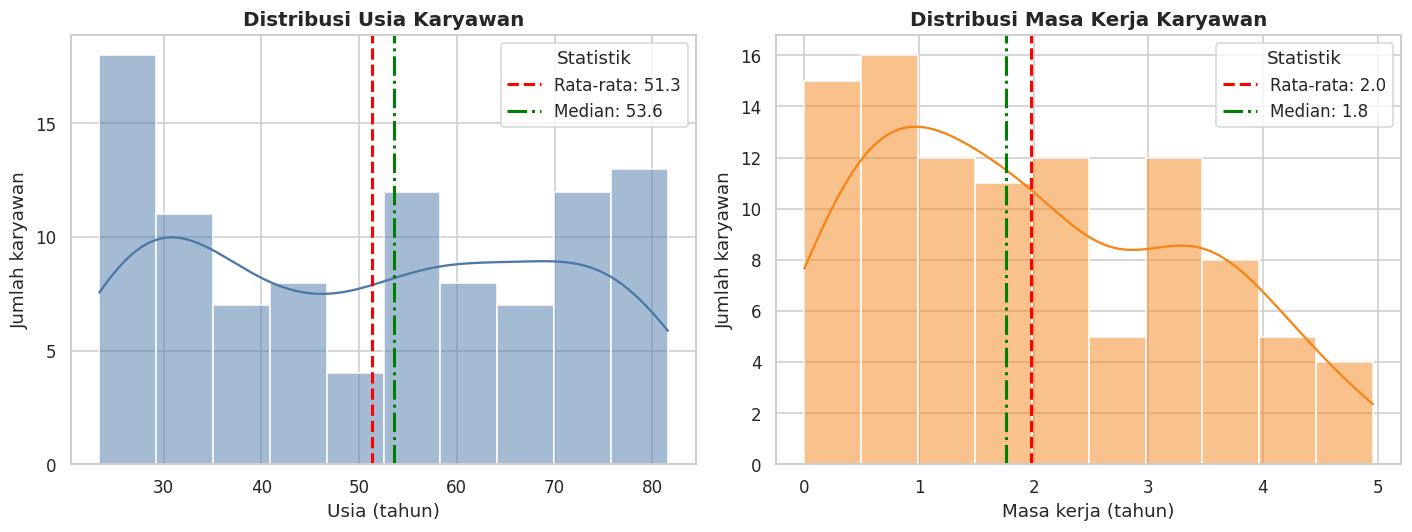

              count   mean    50%    std   min    max
age           100.0  51.27  53.60  19.03  23.4  81.60
tenure_years  100.0   1.98   1.76   1.37   0.0   4.96
Skewness: {'age': 0.04, 'tenure_years': 0.39}
Sebaran kelompok usia: {'30-39': 15, '40-49': 10, '50-59': 18, '60+': 36, '<30': 21}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, warna, judul, xl in [(axes[0], 'age', '#4C78A8', 'Distribusi Usia Karyawan', 'Usia (tahun)'),
                                  (axes[1], 'tenure_years', '#F58518', 'Distribusi Masa Kerja Karyawan', 'Masa kerja (tahun)')]:
    sns.histplot(dv[col], bins=10, kde=True, color=warna, edgecolor='white', ax=ax)
    ax.axvline(dv[col].mean(), color='red', ls='--', lw=2, label=f'Rata-rata: {dv[col].mean():.1f}')
    ax.axvline(dv[col].median(), color='green', ls='-.', lw=2, label=f'Median: {dv[col].median():.1f}')
    ax.set(title=judul, xlabel=xl, ylabel='Jumlah karyawan')
    ax.legend(title='Statistik')
    ax.yaxis.get_major_locator().set_params(integer=True)
simpan('01_histogram_usia_masa_kerja')

print(dv[['age', 'tenure_years']].describe().round(2).T[['count', 'mean', '50%', 'std', 'min', 'max']])
print('Skewness:', dv[['age', 'tenure_years']].skew().round(2).to_dict())
print('Sebaran kelompok usia:', dv['age_group'].value_counts().sort_index().to_dict())

**Interpretasi:**
- **Usia:** rata-rata 51,3 tahun dan median 53,6 tahun, dengan rentang 23,4 sampai 81,6 tahun. Nilai skewness 0,04 menunjukkan distribusi hampir simetris, tetapi bentuknya tidak seperti lonceng: ada dua kelompok besar, yaitu karyawan muda di bawah 30 tahun (21 orang, dengan satu batang tertinggi di sekitar usia 25–29) dan karyawan 60 tahun ke atas (36 orang, 36% dari total). Kelompok 40–49 tahun paling sedikit (10 orang).
- **Masa kerja:** rata-rata 1,98 tahun dan median 1,76 tahun. Distribusi condong ke kanan secara ringan (skewness 0,39): 31 karyawan masa kerjanya kurang dari 1 tahun, sedangkan hanya 29 yang sudah 3 tahun atau lebih. Masa kerja terpanjang hanya 4,96 tahun karena data mulai dari Agustus 2018.
- **Insight:** tenaga kerjanya relatif baru (separuh karyawan bekerja kurang dari sekitar 1,8 tahun) dengan komposisi usia yang timpang antara sangat muda dan sangat senior. Validasi juga menandai 25 karyawan berusia di atas 70 tahun, yang tidak lazim untuk karyawan aktif dan perlu dikonfirmasi ke pemilik data.

### 2. Bar Chart — Jumlah Karyawan per Business Unit dan Division
**Mengapa dipilih:** bar chart membandingkan jumlah antarkategori. Tiga kategori terbanyak diberi warna berbeda agar langsung terlihat.

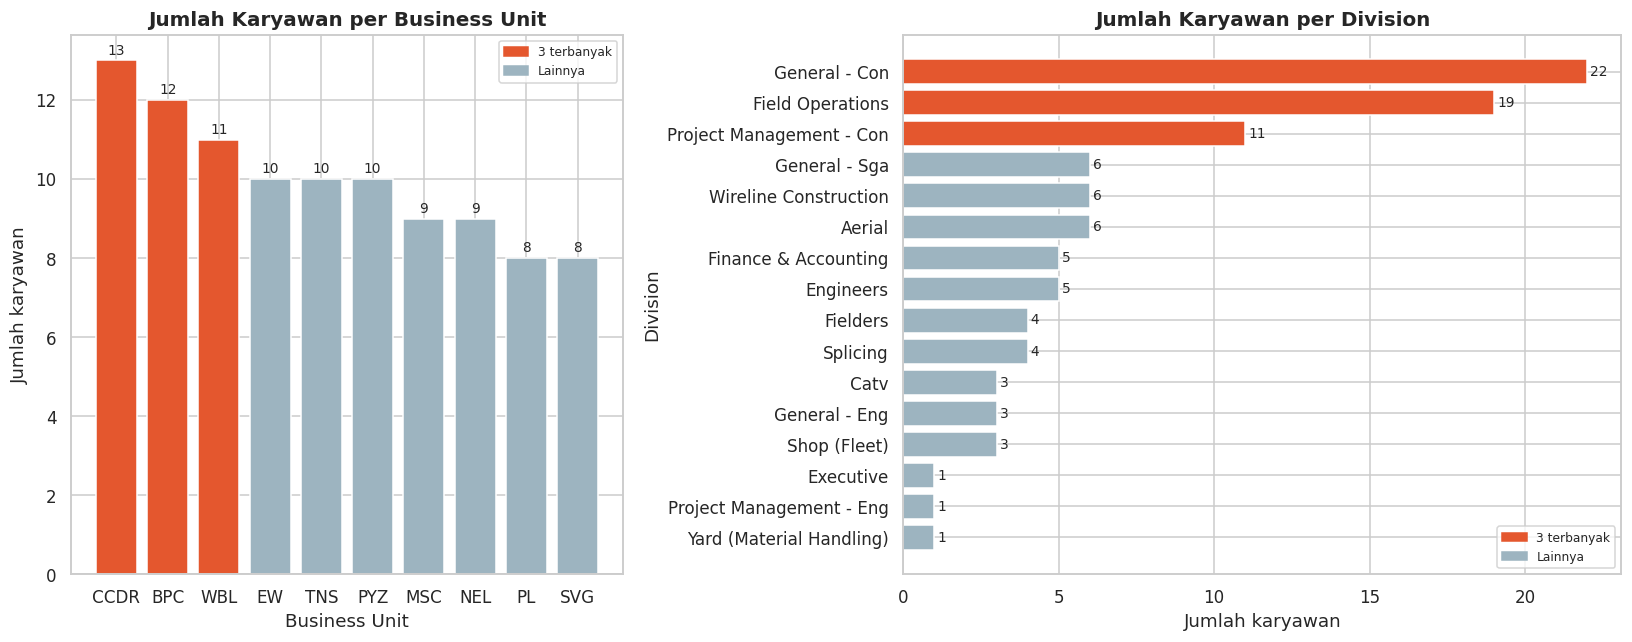

Business unit : {'CCDR': 13, 'BPC': 12, 'WBL': 11, 'EW': 10, 'TNS': 10, 'PYZ': 10, 'MSC': 9, 'NEL': 9, 'PL': 8, 'SVG': 8}
Division teratas: {'General - Con': 22, 'Field Operations': 19, 'Project Management - Con': 11, 'General - Sga': 6, 'Wireline Construction': 6} | jumlah division: 16
Top-3 division = 52% dari karyawan
Department: {'Sales': 93, 'IT/IS': 5, 'Production': 2}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.3]})
bu = dv['business_unit'].value_counts()
dvn = dv['division'].value_counts()
bar_hitung(axes[0], bu, 'Jumlah Karyawan per Business Unit', 'Business Unit', 'Jumlah karyawan')
bar_hitung(axes[1], dvn, 'Jumlah Karyawan per Division', 'Jumlah karyawan', 'Division', horizontal=True)
simpan('02_bar_business_unit_division')

print('Business unit :', bu.to_dict())
print('Division teratas:', dvn.head(5).to_dict(), '| jumlah division:', dvn.size)
print(f'Top-3 division = {dvn.head(3).sum() / len(dv):.0%} dari karyawan')
print('Department:', dv['department_type'].value_counts().to_dict())

**Interpretasi:**
- **Business Unit:** sebaran cukup merata. Jumlah karyawan tiap unit berkisar 8 sampai 13 orang (CCDR 13, BPC 12, WBL 11, terendah PL dan SVG masing-masing 8), sehingga tidak ada unit yang mendominasi.
- **Division:** sebaran sangat tidak merata. Tiga division terbesar (General - Con 22, Field Operations 19, Project Management - Con 11) menampung 52% karyawan, sedangkan tiga division (Executive, Project Management - Eng, Yard) hanya berisi 1 orang. Dari 16 division, 13 division berisi 6 orang atau kurang.
- **Insight:** beban dan pengelolaan SDM terpusat pada dua sampai tiga division, sementara banyak division kecil yang mungkin perlu digabung atau dilihat tersendiri dalam perencanaan SDM. Pada tingkat department, 93 dari 100 karyawan tercatat di `Sales` (IT/IS 5 dan Production 2), padahal nama division seperti Field Operations dan General - Con terdengar non-penjualan. Pengelompokan department perlu dikonfirmasi.

### 3. Count Plot — Performance Score berdasarkan Tipe Karyawan
**Mengapa dipilih:** count plot berkelompok membandingkan sebaran kinerja antar tipe karyawan (data kategorikal vs kategorikal).

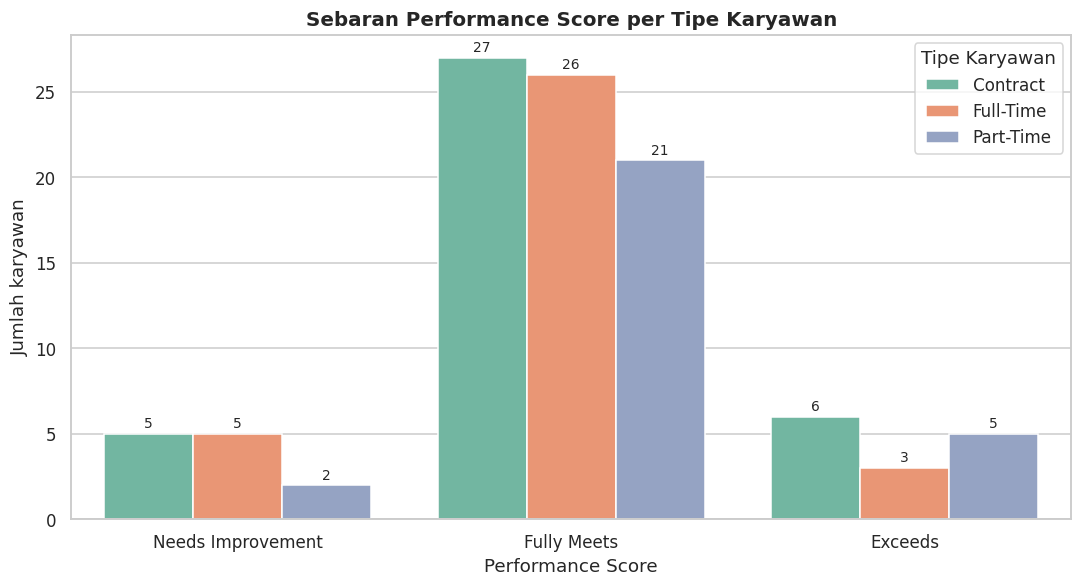

performance_score  Needs Improvement  Fully Meets  Exceeds
employee_type                                             
Contract                           5           27        6
Full-Time                          5           26        3
Part-Time                          2           21        5

Persentase per tipe (baris):
performance_score  Needs Improvement  Fully Meets  Exceeds
employee_type                                             
Contract                        13.2         71.1     15.8
Full-Time                       14.7         76.5      8.8
Part-Time                        7.1         75.0     17.9

Total per performance: {'Fully Meets': 74, 'Exceeds': 14, 'Needs Improvement': 12}


In [14]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.countplot(data=dv, x='performance_score', hue='employee_type', order=URUT_PERF, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fontsize=9, padding=2)
ax.set(title='Sebaran Performance Score per Tipe Karyawan', xlabel='Performance Score', ylabel='Jumlah karyawan')
ax.legend(title='Tipe Karyawan')
simpan('03_countplot_performance_tipe')

ct = pd.crosstab(dv['employee_type'], dv['performance_score'])[URUT_PERF]
print(ct)
print('\nPersentase per tipe (baris):'); print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))
print('\nTotal per performance:', dv['performance_score'].value_counts().to_dict())

**Interpretasi:**
- **Pola umum:** performance score sangat terkonsentrasi pada `Fully Meets` (74% karyawan), disusul `Exceeds` (14%) dan `Needs Improvement` (12%). Polanya mirip di ketiga tipe karyawan.
- **Perbandingan antar tipe:** proporsi `Fully Meets` hampir sama (Contract 71,1%, Full-Time 76,5%, Part-Time 75,0%). Proporsi `Exceeds` tertinggi pada Part-Time (17,9%) dan Contract (15,8%), terendah pada Full-Time (8,8%). Proporsi `Needs Improvement` tertinggi pada Full-Time (14,7%) dan terendah pada Part-Time (7,1%).
- **Insight:** karyawan Full-Time tampak sedikit kurang sering mendapat nilai `Exceeds`, tetapi selisihnya hanya 1 sampai 3 orang per kelompok dengan jumlah sampel 28–38 orang per tipe. Perbedaan ini terlalu kecil untuk disimpulkan sebagai perbedaan kinerja yang nyata; kinerja relatif seragam di semua tipe karyawan.

### 4. Boxplot — Masa Kerja berdasarkan Tipe Terminasi
**Mengapa dipilih:** boxplot menampilkan median, kuartil, dan outlier tiap kelompok; titik hitam adalah data asli. Kategori `Unknown` adalah karyawan yang belum memiliki `exit_date`, sehingga masa kerjanya dihitung sampai tanggal acuan.

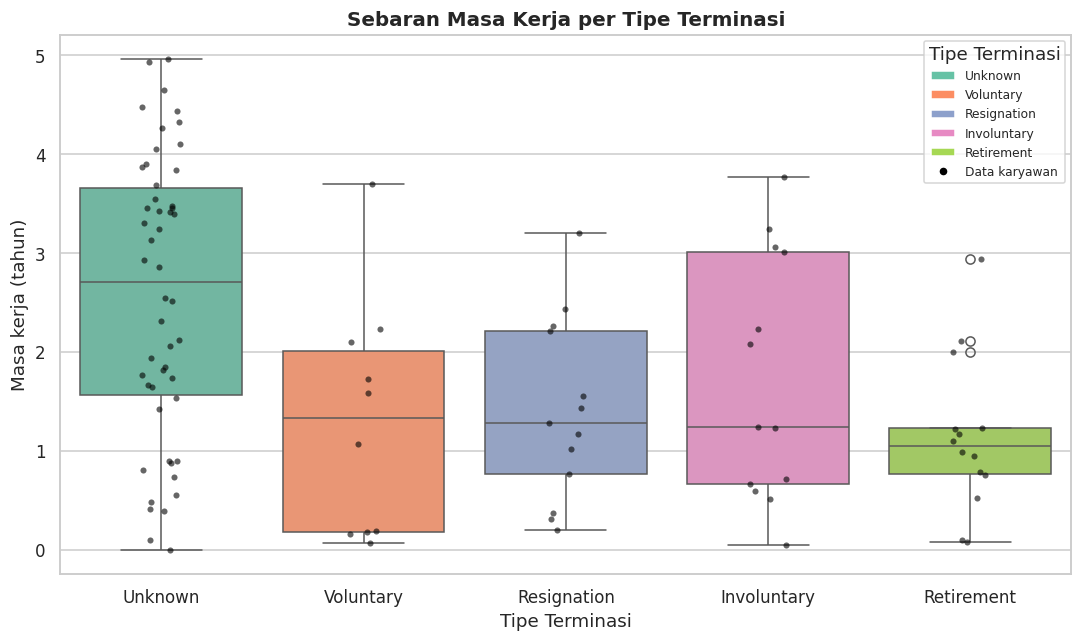

                  count  median  mean   min   max
termination_type                                 
Unknown              50    2.70  2.57  0.00  4.96
Voluntary            10    1.33  1.30  0.07  3.70
Resignation          13    1.28  1.40  0.20  3.20
Involuntary          13    1.24  1.72  0.05  3.77
Retirement           14    1.04  1.14  0.08  2.94


In [15]:
urut = dv.groupby('termination_type')['tenure_years'].median().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=dv, x='termination_type', y='tenure_years', hue='termination_type', order=urut, hue_order=urut,
            palette='Set2', legend=False, ax=ax)
sns.stripplot(data=dv, x='termination_type', y='tenure_years', order=urut, color='black', size=4, alpha=.6, ax=ax)
handles = [Patch(facecolor=WARNA[i], label=k) for i, k in enumerate(urut)]
handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=6, label='Data karyawan'))
ax.legend(handles=handles, title='Tipe Terminasi', fontsize=8)
ax.set(title='Sebaran Masa Kerja per Tipe Terminasi', xlabel='Tipe Terminasi', ylabel='Masa kerja (tahun)')
simpan('04_boxplot_masa_kerja_terminasi')

print(dv.groupby('termination_type')['tenure_years'].agg(['count', 'median', 'mean', 'min', 'max']).round(2).loc[urut])

**Interpretasi:**
- **Karyawan yang sudah keluar:** median masa kerja pada semua tipe terminasi berdekatan, yaitu Voluntary 1,33 tahun, Resignation 1,28 tahun, Involuntary 1,24 tahun, dan Retirement 1,04 tahun. Dari 50 karyawan yang sudah memiliki tanggal keluar, 20 orang (40%) keluar sebelum genap 1 tahun. Terminasi Involuntary paling menyebar (0,05 sampai 3,77 tahun), sedangkan Retirement paling rapat dengan beberapa outlier di sekitar 2 sampai 3 tahun.
- **Kategori `Unknown`:** ini adalah 50 karyawan tanpa tanggal keluar, dengan median masa kerja 2,70 tahun, lebih dari dua kali lipat dari yang sudah keluar (1,19 tahun). Perbedaan ini sebagian bersifat mekanis, karena masa kerja mereka dihitung sampai tanggal acuan sehingga masih terus bertambah.
- **Insight:** karyawan yang keluar cenderung keluar pada tahun pertama sampai kedua, apa pun jenis terminasinya, sehingga risiko turnover terkonsentrasi di awal masa kerja. Ada juga kejanggalan data: karyawan berlabel `Retirement` memiliki rata-rata usia 55,3 tahun dan yang termuda 26,2 tahun, sehingga label ini perlu diverifikasi.

### 5. Boxplot — Rating Karyawan berdasarkan Performance Score
**Mengapa dipilih:** untuk menguji apakah dua ukuran kinerja (`performance_score` dan `current_employee_rating`) saling selaras.

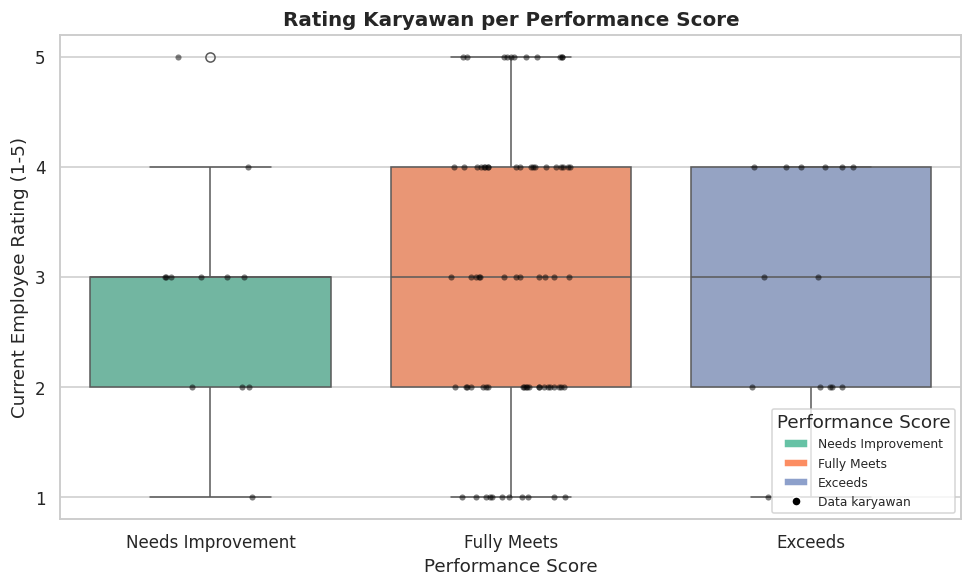

                   count  mean  median
performance_score                     
Needs Improvement     12  2.83     3.0
Fully Meets           74  2.97     3.0
Exceeds               14  2.93     3.0
Korelasi Spearman rating vs performance score: 0.019


In [16]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=dv, x='performance_score', y='current_employee_rating', hue='performance_score', order=URUT_PERF,
            hue_order=URUT_PERF, palette='Set2', legend=False, ax=ax)
sns.stripplot(data=dv, x='performance_score', y='current_employee_rating', order=URUT_PERF, color='black',
              size=4, alpha=.5, jitter=.2, ax=ax)
handles = [Patch(facecolor=WARNA[i], label=k) for i, k in enumerate(URUT_PERF)]
handles.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=6, label='Data karyawan'))
ax.legend(handles=handles, title='Performance Score', fontsize=8, loc='lower right')
ax.set(title='Rating Karyawan per Performance Score', xlabel='Performance Score', ylabel='Current Employee Rating (1-5)')
ax.set_yticks([1, 2, 3, 4, 5])
simpan('05_boxplot_rating_performance')

print(dv.groupby('performance_score')['current_employee_rating'].agg(['count', 'mean', 'median']).round(2).loc[URUT_PERF])
rho = dv['current_employee_rating'].astype(float).corr(dv['performance_score'].map({k: i for i, k in enumerate(URUT_PERF)}).astype(float), method='spearman')
print('Korelasi Spearman rating vs performance score:', round(rho, 3))

**Interpretasi:**
- **Pola:** ketiga kelompok performance score memiliki median rating yang sama, yaitu 3. Rata-rata rating juga hampir identik: `Needs Improvement` 2,83, `Fully Meets` 2,97, dan `Exceeds` 2,93. Koefisien korelasi Spearman antara kedua ukuran hanya 0,02, yang berarti praktis tidak berhubungan.
- **Bukti ketidakselarasan:** karyawan `Exceeds` justru tidak ada yang berating 5 dan 5 dari 14 orang berating 2, sedangkan `Needs Improvement` masih memiliki karyawan dengan rating 4 dan 5. Kotak (kuartil) ketiganya saling tumpang tindih lebar.
- **Insight:** `performance_score` dan `current_employee_rating` tampaknya mengukur hal yang berbeda atau berasal dari periode penilaian yang berbeda, sehingga keduanya tidak bisa saling menggantikan. Sebelum dipakai untuk keputusan SDM, definisi dan waktu penilaian masing-masing kolom perlu dijelaskan oleh pemilik data.

### 6. Scatter Plot — Usia vs Masa Kerja
**Mengapa dipilih:** scatter plot memperlihatkan hubungan dua variabel numerik. Warna menunjukkan gender dan bentuk titik menunjukkan apakah karyawan sudah memiliki tanggal keluar. Garis putus-putus adalah tren linear.

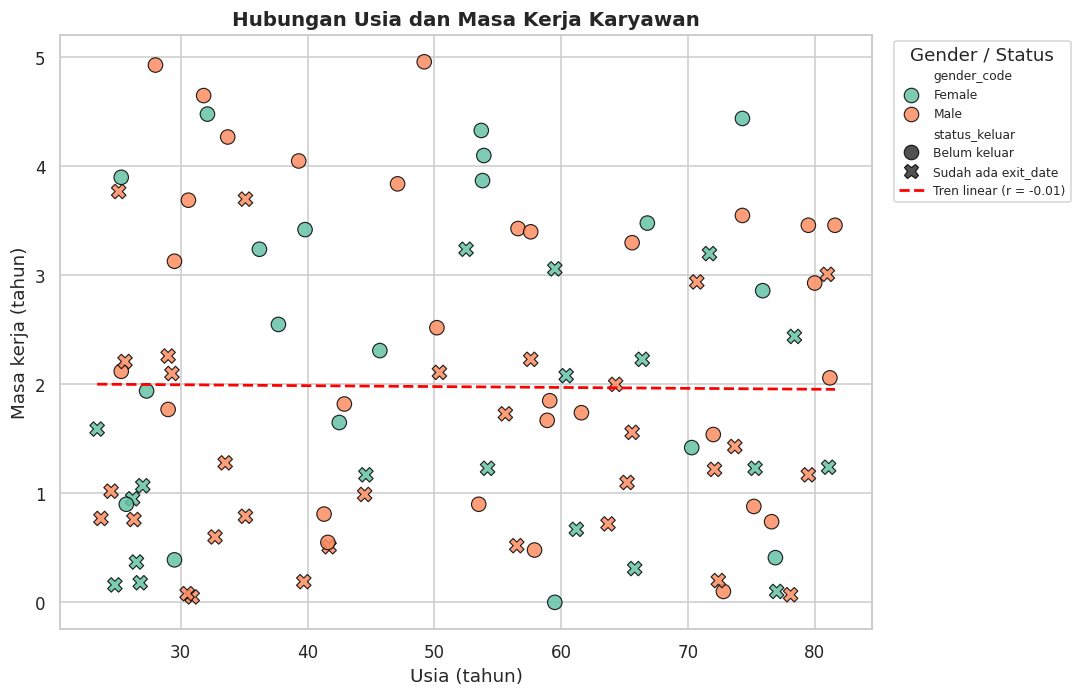

Korelasi Pearson usia vs masa kerja: -0.011 | kemiringan: -0.0008 tahun masa kerja per tahun usia
               age  tenure_years
gender_code                     
Female       50.78          2.01
Male         51.57          1.96


In [17]:
d6 = dv.assign(status_keluar=np.where(dv['is_terminated'], 'Sudah ada exit_date', 'Belum keluar'))
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=d6, x='age', y='tenure_years', hue='gender_code', style='status_keluar', s=90, alpha=.85,
                edgecolor='black', ax=ax)
r = d6['age'].corr(d6['tenure_years'])
m, b = np.polyfit(d6['age'], d6['tenure_years'], 1)
xs = np.linspace(d6['age'].min(), d6['age'].max(), 50)
ax.plot(xs, m * xs + b, 'r--', lw=1.8, label=f'Tren linear (r = {r:.2f})')
ax.set(title='Hubungan Usia dan Masa Kerja Karyawan', xlabel='Usia (tahun)', ylabel='Masa kerja (tahun)')
ax.legend(title='Gender / Status', loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
simpan('06_scatter_usia_masa_kerja')

print('Korelasi Pearson usia vs masa kerja:', round(r, 3), '| kemiringan:', round(m, 4), 'tahun masa kerja per tahun usia')
print(d6.groupby('gender_code')[['age', 'tenure_years']].mean().round(2))

**Interpretasi:**
- **Hubungan:** korelasi usia dan masa kerja sangat lemah (r = -0,01) dan garis tren hampir datar di sekitar 2 tahun. Titik tersebar merata di seluruh bidang: karyawan muda maupun senior sama-sama ada yang masa kerjanya mendekati 0 dan ada yang mendekati 5 tahun.
- **Gender:** kedua gender menyebar di seluruh area plot tanpa kelompok yang terpisah. Rata-rata masa kerja hampir sama (perempuan 2,01 tahun, laki-laki 1,96 tahun) dan rata-rata usia juga mirip (50,8 dan 51,6 tahun).
- **Status keluar:** titik silang (sudah ada tanggal keluar) lebih banyak berada di bagian bawah plot, yaitu masa kerja di bawah sekitar 2 tahun, sejalan dengan temuan pada boxplot masa kerja.
- **Insight:** usia bukan penentu lamanya seseorang bertahan. Karena itu, usia tidak bisa dipakai sebagai dasar memprediksi retensi; faktor lain seperti unit kerja atau kondisi kerja perlu ditelaah.

### 7. Line Chart — Tren Perekrutan dan Karyawan Keluar per Kuartal
**Mengapa dipilih:** line chart menampilkan perubahan dari waktu ke waktu. Garis biru adalah jumlah karyawan masuk (`start_date`), garis oranye jumlah karyawan keluar (`exit_date`), dan garis hijau putus-putus (sumbu kanan) adalah selisih kumulatif masuk dikurangi keluar.

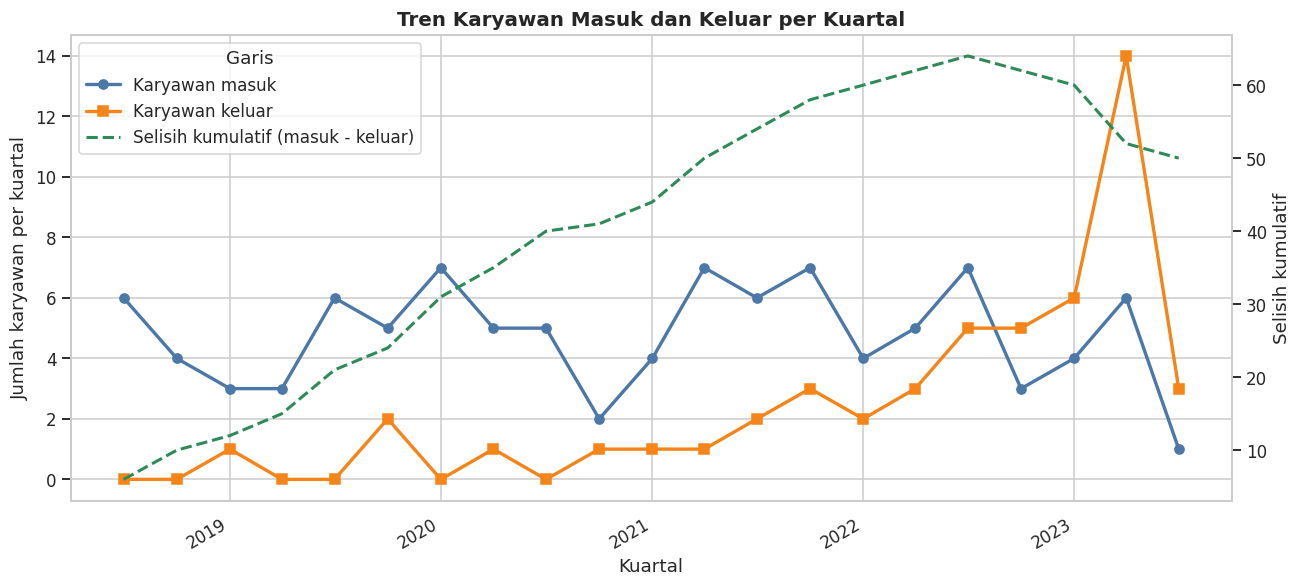

      masuk  keluar
2018     10       0
2019     17       3
2020     19       2
2021     24       7
2022     19      15
2023     11      23
Kuartal masuk tertinggi: 2020Q1 7 | keluar tertinggi: 2023Q2 14
Total masuk: 100 | total keluar: 50 | selisih akhir: 50
Rentang start_date: 2018-08-10 s.d. 2023-08-04 | exit_date: 2019-01-09 s.d. 2023-07-22


In [18]:
awal = min(dv['start_date'].min(), dv['exit_date'].min()).to_period('Q')
akhir = max(dv['start_date'].max(), dv['exit_date'].max()).to_period('Q')
idx = pd.period_range(awal, akhir, freq='Q')
masuk = dv['start_date'].dt.to_period('Q').value_counts().reindex(idx, fill_value=0).sort_index()
keluar = dv['exit_date'].dropna().dt.to_period('Q').value_counts().reindex(idx, fill_value=0).sort_index()
x = idx.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(x, masuk.values, marker='o', lw=2.2, color='#4C78A8', label='Karyawan masuk')
ax.plot(x, keluar.values, marker='s', lw=2.2, color='#F58518', label='Karyawan keluar')
ax.set(title='Tren Karyawan Masuk dan Keluar per Kuartal', xlabel='Kuartal', ylabel='Jumlah karyawan per kuartal')
ax2 = ax.twinx()
ax2.plot(x, (masuk - keluar).cumsum().values, ls='--', lw=2, color='#2E8B57', label='Selisih kumulatif (masuk - keluar)')
ax2.set_ylabel('Selisih kumulatif'); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, title='Garis', loc='upper left')
fig.autofmt_xdate()
simpan('07_line_tren_masuk_keluar')

thn = pd.DataFrame({'masuk': masuk.groupby(masuk.index.year).sum(), 'keluar': keluar.groupby(keluar.index.year).sum()})
print(thn)
print('Kuartal masuk tertinggi:', str(masuk.idxmax()), masuk.max(), '| keluar tertinggi:', str(keluar.idxmax()), keluar.max())
print('Total masuk:', int(masuk.sum()), '| total keluar:', int(keluar.sum()), '| selisih akhir:', int((masuk - keluar).sum()))
print('Rentang start_date:', dv['start_date'].min().date(), 's.d.', dv['start_date'].max().date(),
      '| exit_date:', dv['exit_date'].min().date(), 's.d.', dv['exit_date'].max().date())

**Interpretasi:**
- **Karyawan masuk:** jumlah per tahun naik dari 10 (2018, hanya sejak Agustus) ke 17 (2019), 19 (2020), dan puncaknya 24 pada 2021, lalu turun menjadi 19 (2022) dan 11 (2023, sampai Agustus). Per kuartal, puncaknya 7 orang.
- **Karyawan keluar:** nyaris tidak ada pada awal periode (0 pada 2018, 3 pada 2019, 2 pada 2020), kemudian meningkat tajam menjadi 7 (2021), 15 (2022), dan 23 (2023, sampai Juli). Kuartal kedua 2023 mencatat lonjakan tertinggi, yaitu 14 orang keluar dalam satu kuartal.
- **Selisih kumulatif:** garis hijau naik terus sampai puncak 64 pada kuartal ketiga 2022, lalu turun menjadi 50 karena sejak itu jumlah yang keluar melampaui jumlah yang masuk. Pada 2023 jumlah yang keluar (23) sudah dua kali lipat yang masuk (11).
- **Insight:** perusahaan beralih dari fase ekspansi (2018–2021) ke fase penyusutan (sejak pertengahan 2022), dengan perekrutan melambat saat turnover meningkat. Catatan: kuartal ketiga 2023 belum lengkap karena data berhenti Agustus 2023, dan selisih kumulatif ini adalah indikator kasar karena 17 karyawan berstatus `Future Start` serta 33 berstatus `Active` pun tercatat memiliki tanggal keluar.

### 8. Heatmap — Korelasi Variabel Numerik
**Mengapa dipilih:** heatmap meringkas seluruh hubungan antarvariabel dalam satu matriks. Merah = korelasi positif, biru = negatif, angka = koefisien Pearson.

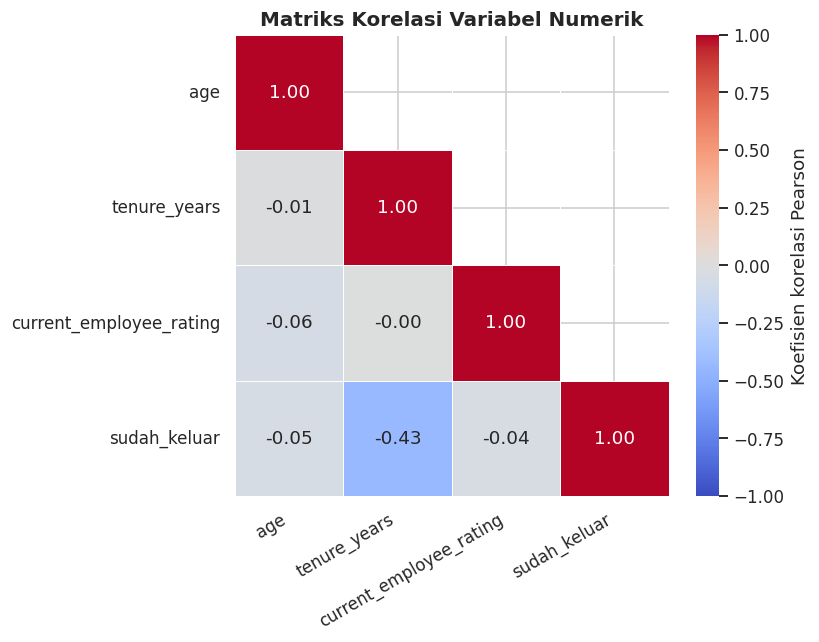

sudah_keluar             tenure_years              -0.431
current_employee_rating  age                       -0.062
sudah_keluar             age                       -0.050
                         current_employee_rating   -0.040
tenure_years             age                       -0.011
current_employee_rating  tenure_years              -0.003


In [19]:
num = dv[['age', 'tenure_years', 'current_employee_rating']].astype(float).assign(sudah_keluar=dv['is_terminated'].astype(int))
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=.5,
            cbar_kws={'label': 'Koefisien korelasi Pearson'}, ax=ax)
ax.set_title('Matriks Korelasi Variabel Numerik')
plt.xticks(rotation=30, ha='right')
simpan('08_heatmap_korelasi')

pasang = corr.where(~mask & ~np.eye(len(corr), dtype=bool)).stack().dropna()
print(pasang.round(3).sort_values(key=abs, ascending=False).to_string())

**Interpretasi:**
- **Pola:** hubungan terkuat adalah antara `sudah_keluar` dan `tenure_years` (r = -0,43, sedang dan negatif): karyawan yang sudah keluar memiliki masa kerja lebih pendek. Sebagian dari hubungan ini bersifat mekanis, karena masa kerja karyawan yang belum keluar dihitung sampai tanggal acuan.
- **Pasangan lainnya:** seluruh korelasi lain sangat lemah (|r| ≤ 0,06), yaitu usia dengan masa kerja (-0,01), usia dengan rating (-0,06), dan rating dengan masa kerja (0,00). Rating tidak berhubungan dengan siapa pun, baik usia, masa kerja, maupun status keluar (-0,04).
- **Insight:** pada data ini, usia, masa kerja, dan rating bergerak independen satu sama lain. Satu-satunya sinyal berarti adalah turnover terjadi pada karyawan dengan masa kerja pendek. Dengan hanya 100 data, korelasi ini juga tidak membuktikan hubungan sebab-akibat.

### 9. Heatmap — Tipe Karyawan vs Klasifikasi Karyawan
**Mengapa dipilih:** tabel silang antar dua kategori membantu memeriksa konsistensi data. Jika kedua kolom selaras, angka akan menumpuk di diagonal (Full-Time dengan Full-Time, dst).

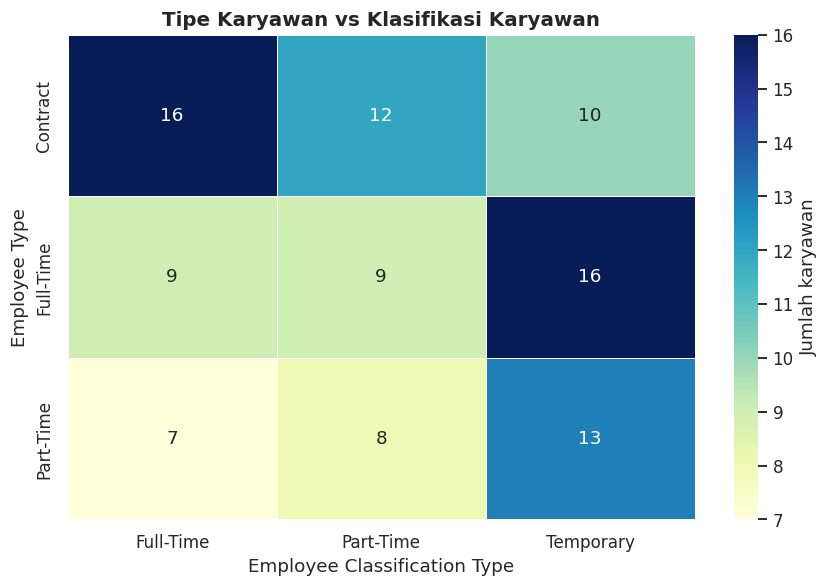

employee_classification_type  Full-Time  Part-Time  Temporary
employee_type                                                
Contract                             16         12         10
Full-Time                             9          9         16
Part-Time                             7          8         13

Nilai yang sama pada kedua kolom: 17 dari 100 karyawan (17%)


In [20]:
tab = pd.crosstab(dv['employee_type'], dv['employee_classification_type'])
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(tab, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5, cbar_kws={'label': 'Jumlah karyawan'}, ax=ax)
ax.set(title='Tipe Karyawan vs Klasifikasi Karyawan', xlabel='Employee Classification Type', ylabel='Employee Type')
simpan('09_heatmap_tipe_klasifikasi')

print(tab)
selaras = sum(tab.loc[k, k] for k in tab.index if k in tab.columns)
print(f'\nNilai yang sama pada kedua kolom: {selaras} dari {len(dv)} karyawan ({selaras / len(dv):.0%})')

**Interpretasi:**
- **Pola:** jika kedua kolom selaras, angka akan menumpuk di diagonal. Kenyataannya hanya 17 dari 100 karyawan (17%) yang bernilai sama pada kedua kolom (Full-Time dengan Full-Time sebanyak 9 dan Part-Time dengan Part-Time sebanyak 8). Dua sel terbesar justru tidak selaras: Contract dengan klasifikasi Full-Time (16) dan Full-Time dengan klasifikasi Temporary (16).
- **Kejanggalan:** 16 dari 34 karyawan bertipe Full-Time (47%) diklasifikasikan Temporary. Kolom klasifikasi juga tidak memiliki kategori Contract, sehingga kosakata kedua kolom berbeda.
- **Insight:** `employee_type` dan `employee_classification_type` kemungkinan mengukur hal yang berbeda atau salah satunya terisi tidak akurat. Keduanya tidak boleh dipakai bergantian dalam analisis sebelum definisinya dikonfirmasi.

### 10. Donut Chart — Komposisi Status Karyawan dan Gender
**Mengapa dipilih:** donut chart menampilkan proporsi bagian terhadap keseluruhan untuk kategori yang sedikit (2–3 kelompok).

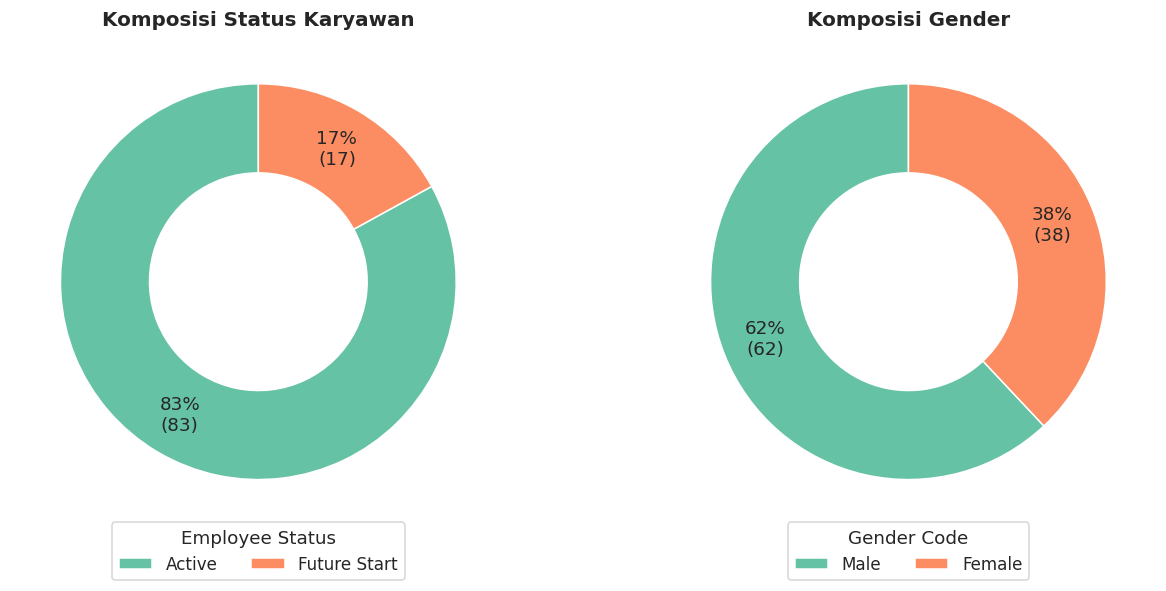

Status: {'Active': 83, 'Future Start': 17}
Gender: {'Male': 62, 'Female': 38}
Gender per status:
gender_code      Female  Male
employee_status              
Active               32    51
Future Start          6    11


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, col, judul in [(axes[0], 'employee_status', 'Komposisi Status Karyawan'), (axes[1], 'gender_code', 'Komposisi Gender')]:
    vc = dv[col].value_counts()
    wedges, _, autotexts = ax.pie(vc.values, autopct=lambda p: f'{p:.0f}%\n({p * vc.sum() / 100:.0f})', startangle=90,
                                  colors=WARNA[:len(vc)], pctdistance=.78, wedgeprops={'width': .45, 'edgecolor': 'white'})
    ax.legend(wedges, vc.index, title=col.replace('_', ' ').title(), loc='lower center', bbox_to_anchor=(.5, -.12), ncol=len(vc))
    ax.set_title(judul)
simpan('10_donut_status_gender')

print('Status:', dv['employee_status'].value_counts().to_dict())
print('Gender:', dv['gender_code'].value_counts().to_dict())
print('Gender per status:'); print(pd.crosstab(dv['employee_status'], dv['gender_code']))

**Interpretasi:**
- **Status:** 83% karyawan berstatus `Active` dan 17% `Future Start`.
- **Gender:** 62% laki-laki dan 38% perempuan, atau sekitar 1,6 laki-laki untuk tiap 1 perempuan. Komposisi ini konsisten di kedua status (Active: 51 laki-laki dan 32 perempuan; Future Start: 11 dan 6).
- **Insight:** komposisi gender timpang tetapi stabil, sehingga tidak ada indikasi perekrutan terbaru mengubah keseimbangan. Namun, kelompok `Future Start` bermasalah secara logika: seluruh 17 orang sudah memiliki tanggal keluar dan tanggal masuknya sudah terjadi (bukan lagi di masa depan). Artinya, status ini kemungkinan tidak diperbarui atau salah isi.

### 11. Plotly (Interaktif) — Sunburst Department dan Division
**Mengapa dipilih:** sunburst menampilkan hierarki (department di tengah, division di luar). Arahkan kursor untuk melihat jumlah dan klik sebuah bagian untuk memperbesarnya. Grafik juga disimpan sebagai file HTML di Drive.

In [22]:
agg = dv.groupby(['department_type', 'division']).size().reset_index(name='jumlah_karyawan')
fig = px.sunburst(agg, path=['department_type', 'division'], values='jumlah_karyawan',
                  title='Struktur Karyawan: Department dan Division (Interaktif)',
                  labels={'jumlah_karyawan': 'Jumlah karyawan', 'department_type': 'Department', 'division': 'Division'})
fig.update_traces(textinfo='label+value', hovertemplate='<b>%{label}</b><br>Jumlah karyawan: %{value}<extra></extra>')
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig.write_html(f'{VIS_DIR}/11_plotly_sunburst_department_division.html')
fig.show()

print(agg.sort_values('jumlah_karyawan', ascending=False).head(8).to_string(index=False))
print('Jumlah department:', agg['department_type'].nunique(), '| jumlah division:', agg['division'].nunique())

department_type                 division  jumlah_karyawan
          Sales            General - Con               21
          Sales         Field Operations               18
          Sales Project Management - Con               10
          Sales            General - Sga                6
          Sales    Wireline Construction                6
          Sales                Engineers                5
          Sales                 Splicing                4
          Sales                 Fielders                4
Jumlah department: 3 | jumlah division: 16


**Interpretasi:**
- **Struktur:** lingkaran dalam menunjukkan `Sales` mendominasi dengan 93 karyawan (93%), sedangkan IT/IS hanya 5 dan Production 2. Di dalam Sales, tiga division terbesar adalah General - Con (21), Field Operations (18), dan Project Management - Con (10).
- **Insight:** hierarki organisasi sangat tidak seimbang: hampir seluruh karyawan berada di satu department, sehingga analisis per department tidak informatif dan analisis per division lebih bermakna. Pola ini sejalan dengan Bar Chart nomor 2, dan memperkuat dugaan bahwa pengelompokan department perlu ditinjau. Gunakan fitur klik pada grafik interaktif untuk memperbesar satu department atau division.

---
## 12. Kesimpulan

**Hasil cleansing.** Dataset mentah 3.000 baris × 26 kolom ternyata hanya berisi 100 baris data; 2.900 baris kosong total dibuang. Setelah itu, tiga format tanggal masuk/keluar/lahir yang bercampur (`20-Sep-19`, `30-08-1965`, `7/10/1969`) disatukan menjadi satu format `YYYY-MM-DD`, spasi berlebih dirapikan (mis. `Production       `), kategori dibakukan (`Unk` menjadi `Unknown`), dan nama kolom diseragamkan ke `snake_case`. Tidak ada duplikat maupun `emp_id` kembar, dan tidak ada tanggal yang gagal dibaca. `exit_date` sengaja dibiarkan kosong untuk 50 karyawan karena kosong berarti belum keluar. Empat kolom enrichment ditambahkan (`age`, `age_group`, `tenure_years`, `is_terminated`) dan dataset bersih disimpan ke Drive berdampingan dengan data mentah.

**Temuan analisis.** Tenaga kerja relatif baru (median masa kerja 1,76 tahun) dengan usia yang terbelah antara kelompok di bawah 30 tahun dan di atas 60 tahun. Business unit tersebar merata, tetapi division terpusat (tiga terbesar menampung 52%) dan 93% karyawan berada di department Sales. Kinerja seragam di semua tipe karyawan (74% `Fully Meets`). Usia tidak berhubungan dengan masa kerja, dan karyawan yang keluar umumnya pergi dalam 1–1,5 tahun pertama. Tren menunjukkan fase ekspansi sampai 2021 yang berbalik menjadi penyusutan sejak pertengahan 2022: pada 2023 yang keluar (23) dua kali lipat yang masuk (11).

**Catatan kualitas data yang perlu diklarifikasi ke pemilik data** (tidak diubah otomatis oleh notebook ini):
1. 33 karyawan berstatus `Active` dan 17 berstatus `Future Start` tetapi memiliki `exit_date`; seluruh karyawan `Future Start` juga sudah melewati tanggal masuknya.
2. `performance_score` dan `current_employee_rating` hampir tidak berkorelasi (Spearman 0,02).
3. `employee_type` dan `employee_classification_type` hanya selaras pada 17% karyawan.
4. 25 karyawan berusia di atas 70 tahun, dan terminasi `Retirement` tercatat pada karyawan berusia sampai 26 tahun.
5. Tanggal lahir bergaris miring (43 data) ambigu antara hari/bulan dan bulan/hari; notebook membacanya sebagai hari/bulan/tahun.

Karena hanya 100 karyawan yang dianalisis, seluruh pola di atas bersifat indikatif dan perlu diuji ulang pada data yang lebih besar.